# MATH 70116, Deep Learning
## Autumn 2026
## Lecturer: Tom Hadfield
# Universal approximation theorem : Examples

Following p26-27 of the lecture notes, take $g(x) = sin(x)$, $f = {\mathcal{N}}_2 (I, d, 1, g, Id)$, and $u(x) = cos(\alpha x)$, for $x \in K = [-1, 1]$. Given $\epsilon > 0$, we want to choose $d$ so that ${|| u - f ||}_{sup, K} < \epsilon$

Note: in this example, there is an exact $d=1$ solution. Using the double-angle formula,
$$sin(\alpha x + \pi/2) = sin(\alpha x) cos(\pi/2) + cos(\alpha x) sin(\pi/2) = cos(\alpha x)$$
$$\Rightarrow \quad \quad u(x) = 1.0 * g(wx + b) + 0.0$$
with $w = \alpha$, $\quad b = \pi/2$

In fact, we can use this to get an exact solution for any $d \ge 1$. 

Take $W^1_{i1} = \alpha$, $\quad b^1_i = \pi/2$, for $1 \le i \le d$

and $W^2_{1j} = 1/d$, $\quad b^2_{11} = 0$, for $1 \le j \le d$.

So we have constructed the global minimum. Does training our neural network find this minimum?


In [1]:
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
import matplotlib.pyplot as plt
import math

### Define $u(x) = cos(\alpha x)$

In [2]:
alpha = 2.0 * np.pi
min_x = -1.0
max_x = 1.0
N = 2**10 + 1

X = np.linspace(min_x, max_x, N)
# y = u(x)
y = np.cos(alpha * X)

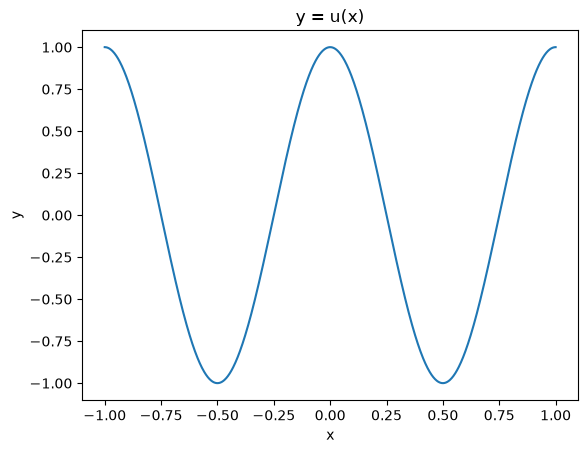

In [3]:
plt.plot(X,y)
plt.title("y = u(x)")
plt.xlabel("x")
plt.ylabel("y")
plt.show()

In [4]:
# define our custom activation function

class CustomActivation(nn.Module):
    def forward(self, x):
        return torch.sin(x)

In [5]:
d = 50
input_dim = 1
output_dim = 1

f = nn.Sequential(
    nn.Linear(input_dim, d),
    CustomActivation(),
    nn.Linear(d, output_dim),
)

In [6]:
eta = 0.01 # learning rate
optimizer = torch.optim.Adam(f.parameters(), lr=eta)
loss_fn = nn.MSELoss()

The functions <code>train_model</code> and <code>model_predict</code> are defined below. Scroll down and run these cells. 

In [10]:
num_epochs = 50

train = train_model(
    f,
    X,
    y,
    loss_fn,
    optimizer,
    epochs=num_epochs,
    batch_size=32,
    validation_split=0.2,
    verbose_every=1)

n_total =  1025 n_val =  205 n_train =  820
Epoch 1/50, loss: 0.5204, val_loss: 0.7458
Epoch 2/50, loss: 0.5231, val_loss: 0.9186
Epoch 3/50, loss: 0.5138, val_loss: 1.2531
Epoch 4/50, loss: 0.5018, val_loss: 0.8438
Epoch 5/50, loss: 0.4963, val_loss: 1.1608
Epoch 6/50, loss: 0.4872, val_loss: 1.1864
Epoch 7/50, loss: 0.4878, val_loss: 1.6971
Epoch 8/50, loss: 0.4451, val_loss: 1.9854
Epoch 9/50, loss: 0.3670, val_loss: 4.9741
Epoch 10/50, loss: 0.2253, val_loss: 8.0766
Epoch 11/50, loss: 0.1219, val_loss: 9.2552
Epoch 12/50, loss: 0.0898, val_loss: 10.4218
Epoch 13/50, loss: 0.0795, val_loss: 8.1736
Epoch 14/50, loss: 0.0709, val_loss: 6.8587
Epoch 15/50, loss: 0.0647, val_loss: 5.8502
Epoch 16/50, loss: 0.0579, val_loss: 4.8276
Epoch 17/50, loss: 0.0509, val_loss: 3.8980
Epoch 18/50, loss: 0.0431, val_loss: 2.7061
Epoch 19/50, loss: 0.0346, val_loss: 2.1630
Epoch 20/50, loss: 0.0267, val_loss: 1.1358
Epoch 21/50, loss: 0.0190, val_loss: 0.7649
Epoch 22/50, loss: 0.0123, val_loss: 0.4

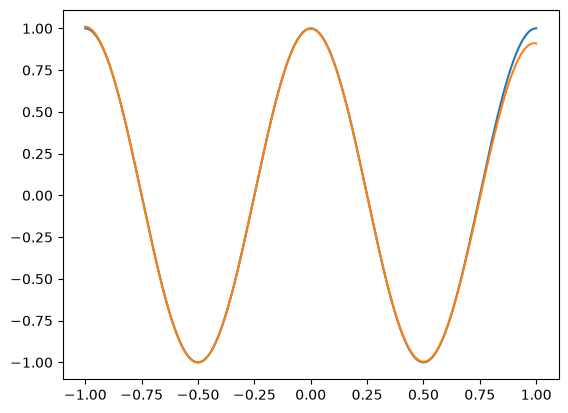

In [11]:
# Evaluate on the training data
y_pred = model_predict(f,X)

plt.plot(X, y)
plt.plot(X, y_pred)
plt.show()

### Calculate ${{||} u - f {||}}_{sup, K}$

In [12]:
print("y.shape = ", y.shape)
print("y_pred.shape = ", y_pred.shape)

print("sup norm = ", np.max(abs(y-y_pred.reshape(-1))))

y.shape =  (1025,)
y_pred.shape =  (1025, 1)
sup norm =  0.09041464328765869


### Calculate ${||u - f||}_{L^p (K)} = {( {\int_{K}} {|u(x) - f(x)|}^{p} dx)}^{1/p}$

In [13]:
p = 2
diff = y-y_pred.reshape(-1)
diff_to_the_p = diff ** p
step_size = (max_x - min_x)/(N-1)
print("step_size = ", step_size) 
this_integral = step_size * np.sum(diff_to_the_p)
Lp_norm = this_integral ** (1.0 / p)

print("For p =", p, ", Lp norm = ", Lp_norm)

step_size =  0.001953125
For p = 2 , Lp norm =  0.028596095285576436


### Evaluate on some new data

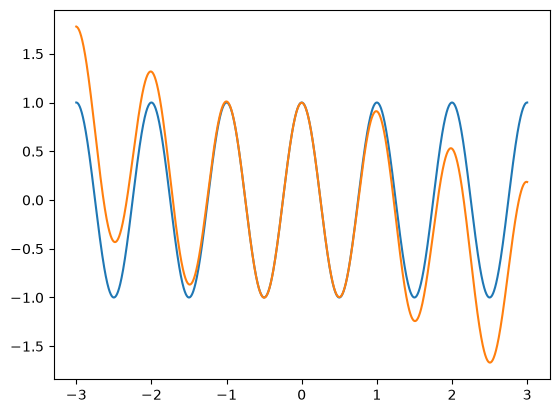

In [14]:
scale_factor = 2.0

X_new = np.linspace(
    min_x - (scale_factor - 1.0) * (max_x - min_x), 
    max_x + (scale_factor - 1.0) * (max_x - min_x), 
    int(N * scale_factor))
y_new = np.cos(2.0 * np.pi * X_new)
y_pred_new = model_predict(f,X_new)

plt.plot(X_new, y_new)
plt.plot(X_new, y_pred_new)
plt.show()

### Evaluate on some new data (part 2)

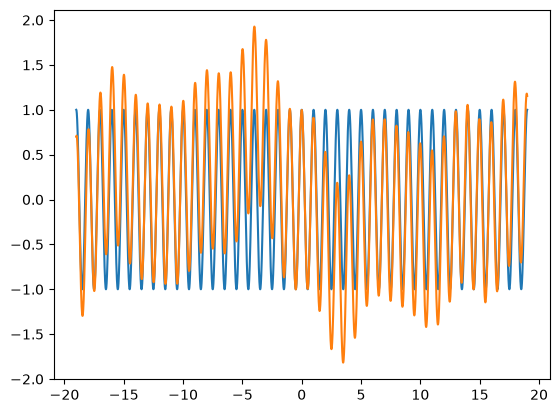

In [19]:
scale_factor = 10.0

X_new = np.linspace(
    min_x - (scale_factor - 1.0) * (max_x - min_x), 
    max_x + (scale_factor - 1.0) * (max_x - min_x), 
    int(N * scale_factor))
y_new = np.cos(2.0 * np.pi * X_new)
y_pred_new = model_predict(f,X_new)

plt.plot(X_new, y_new)
plt.plot(X_new, y_pred_new)
plt.show()

## Inspect the trained model
Note that <code>plot_histogram_of_values</code> is defined below

summary stats for input values
type : <class 'numpy.ndarray'>
shape : (50,)
min : -1.4554222
max : 6.292825
mean : 0.055126894
std : 1.0202931
Histogram counts: [ 0  0  2  9 14 18  6  0  0  0  0  0  0  0  0  0  0  0  1  0]


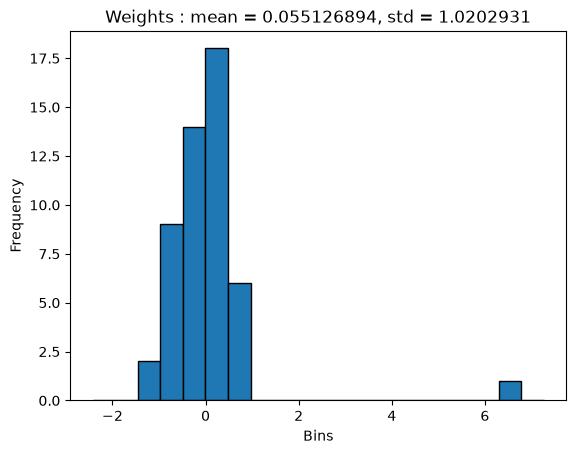

summary stats for input values
type : <class 'numpy.ndarray'>
shape : (50,)
min : -0.7086483
max : 1.5759991
mean : 0.072932646
std : 0.47154725
Histogram counts: [0 1 1 5 7 2 9 8 2 4 3 2 4 0 1 0 0 0 1 0]


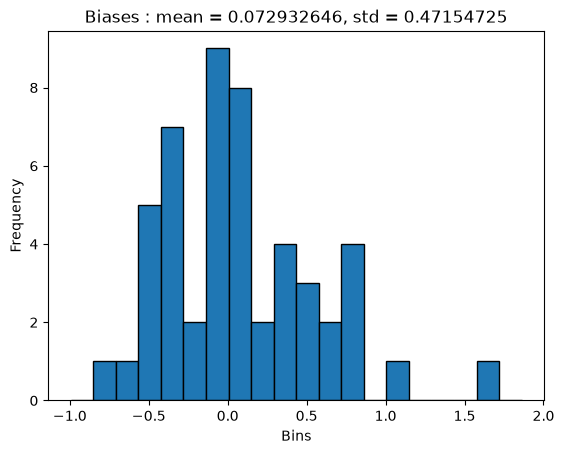

In [20]:
w_np = f[0].weight.detach().numpy()
b_np = f[0].bias.detach().numpy()

plot_histogram_of_values(w_np, num_bins=20, title_text = "Weights :")
plot_histogram_of_values(b_np, num_bins=20, title_text = "Biases :")

### Exercise : Try a different $u(x)$, e.g. $u(x) = (x^2 - 1)^2$
### Exercise : Try a different $g(x)$ - you choose

### Now let's use a polynomial activation function $g(x) = x^n$
### to try to approximate $u(x) = |x|$ 

In [21]:
min_x = -1.0
max_x = 1.0
N = 2**10 + 1

X = np.linspace(min_x, max_x, N)
# y = u(x)
y = abs(X)

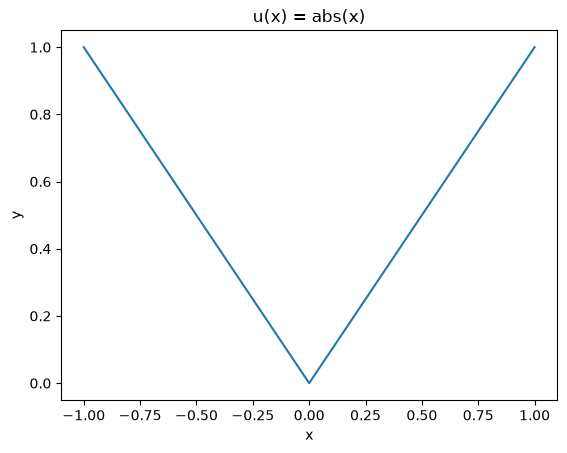

In [22]:
plt.plot(X,y)
plt.title("u(x) = abs(x)")
plt.xlabel("x")
plt.ylabel("y")
plt.show()

In [23]:
# define our custom polynomial activation function

poly_deg = 4

class CustomPolynomialActivation(nn.Module):
    def forward(self, x):
        n = poly_deg
        return x ** n

In [24]:
d = 1000
input_dim = 1
output_dim = 1

f_poly = nn.Sequential(
    nn.Linear(input_dim, d),
    CustomPolynomialActivation(),
    nn.Linear(d, output_dim),
)

In [25]:
eta = 0.01 # learning rate
optimizer = torch.optim.Adam(f_poly.parameters(), lr=eta)
loss_fn = nn.MSELoss()

In [26]:
num_epochs = 50

train = train_model(
    f_poly,
    X,
    y,
    loss_fn,
    optimizer,
    epochs=num_epochs,
    batch_size=32,
    validation_split=0.2,
    verbose_every=1)

n_total =  1025 n_val =  205 n_train =  820
Epoch 1/50, loss: 2.9312, val_loss: 6.2887
Epoch 2/50, loss: 0.1263, val_loss: 0.0217
Epoch 3/50, loss: 0.0136, val_loss: 0.2148
Epoch 4/50, loss: 0.0070, val_loss: 0.2907
Epoch 5/50, loss: 0.0058, val_loss: 0.2873
Epoch 6/50, loss: 0.0044, val_loss: 0.4171
Epoch 7/50, loss: 0.0038, val_loss: 0.3862
Epoch 8/50, loss: 0.0033, val_loss: 0.4945
Epoch 9/50, loss: 0.0029, val_loss: 0.4542
Epoch 10/50, loss: 0.0026, val_loss: 0.5224
Epoch 11/50, loss: 0.0024, val_loss: 0.3459
Epoch 12/50, loss: 0.0020, val_loss: 0.2953
Epoch 13/50, loss: 0.0017, val_loss: 0.2483
Epoch 14/50, loss: 0.0016, val_loss: 0.0963
Epoch 15/50, loss: 0.0016, val_loss: 0.0552
Epoch 16/50, loss: 0.0015, val_loss: 0.0462
Epoch 17/50, loss: 0.0016, val_loss: 0.0301
Epoch 18/50, loss: 0.0019, val_loss: 0.0246
Epoch 19/50, loss: 0.0020, val_loss: 0.0285
Epoch 20/50, loss: 0.0014, val_loss: 0.0507
Epoch 21/50, loss: 0.0018, val_loss: 0.0087
Epoch 22/50, loss: 0.0021, val_loss: 0.02

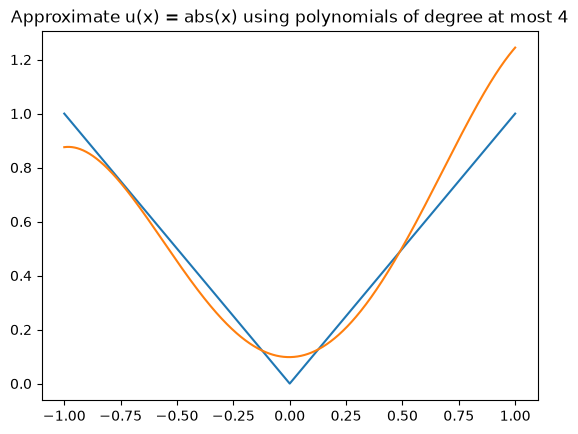

In [27]:
# Evaluate on the training data
y_pred = model_predict(f_poly,X)

this_title = "Approximate u(x) = abs(x) using polynomials of degree at most " + str(poly_deg)
plt.plot(X, y)
plt.plot(X, y_pred)
plt.title(this_title)
plt.show()

### Calculate ${|| u - f ||}_{sup, K}$

In [28]:
print("y.shape = ", y.shape)
print("y_pred.shape = ", y_pred.shape)

print("sup norm = ", np.max(abs(y-y_pred.reshape(-1))))

y.shape =  (1025,)
y_pred.shape =  (1025, 1)
sup norm =  0.24466252326965332


### Calculate ${||u - f||}_{L^p (K)} = {( \int_K |u(x) - f(x)|^p dx)}^{1/p}$

In [29]:
p = 2
diff = y - y_pred.reshape(-1)
diff_to_the_p = diff ** p
step_size = (max_x - min_x)/(N-1)
print("step_size = ", step_size) 
this_integral = step_size * np.sum(diff_to_the_p)
Lp_norm = this_integral ** (1.0 / p)

print("For p =", p, ", Lp norm = ", Lp_norm)

step_size =  0.001953125
For p = 2 , Lp norm =  0.12885986784394926


### Exercise: Can you improve the approximation by increasing the hidden dimension $d$, and/or increasing the degree of the polynomial? 
### Exercise: what does this trained model look like on a larger range of $x$, e.g. $[-2,2]$ ?

In [7]:
def train_model(
    model,
    X,
    y,
    loss_fn,
    optimizer,
    epochs=100,
    batch_size=32,
    metrics=None,
    X_val=None,
    y_val=None,
    validation_split=0.0,
    verbose_every=10,
    device=None,
):
    """
    Generic training loop for a PyTorch model.

    Parameters
    ----------
    model : nn.Module
    X, y : torch.Tensor or np.ndarray  -- training data
    loss_fn : callable, e.g. nn.MSELoss(), nn.BCELoss()
    optimizer : torch.optim.Optimizer
    epochs : int
    batch_size : int
    metrics : dict[str, callable] or None
        Each callable takes (y_pred, y_true) and returns a float.
    X_val, y_val : optional validation data (same format as X, y)
        validation_split : float in [0.0, 1.0)
        Fraction of (X, y) to hold out as validation data, taken from the END of the dataset. 
        Ignored if X_val and y_val are both explicitly provided.
    verbose_every : int -- print progress every N epochs (0 to disable)
    device : torch.device or None -- defaults to CUDA if available, else CPU

    Returns
    -------
    history : dict of lists, e.g. {"loss": [...], "val_loss": [...], "accuracy": [...]}
    """
    if not (0.0 <= validation_split < 1.0):
        raise ValueError("validation_split must be in [0.0, 1.0)")

    if device is None:
        device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    model.to(device)

    def to_tensor(a):
        if isinstance(a, np.ndarray):
            return torch.from_numpy(a).float()
        return a.float()

    X = to_tensor(X)
    #X = (to_tensor(X)).unsqueeze(-1)
    y = (to_tensor(y)).unsqueeze(-1)

    # Handle validation_split (only if X_val/y_val not already given)
    if X_val is None and y_val is None and validation_split > 0.0:
        n_total = X.shape[0]
        n_val = int(round(n_total * validation_split))
        n_train = n_total - n_val

        X_val = X[n_train:]
        y_val = y[n_train:]
        X = X[:n_train]
        y = y[:n_train]
        print("n_total = ", n_total, "n_val = ", n_val, "n_train = ", n_train)

    dataset = TensorDataset(X, y)
    loader = DataLoader(dataset, batch_size=batch_size, shuffle=True)

    has_val = X_val is not None and y_val is not None
    if has_val:
        X_val = to_tensor(X_val).to(device)
        y_val = to_tensor(y_val).to(device)

    metrics = metrics or {}

    history = {"loss": []}
    history.update({name: [] for name in metrics})
    if has_val:
        history["val_loss"] = []
        history.update({f"val_{name}": [] for name in metrics})

    for epoch in range(epochs):
        model.train()
        running_loss = 0.0
        running_metrics = {name: 0.0 for name in metrics}
        n_samples = 0

        i = 0
        for X_batch, y_batch in loader:
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)
            i += 1

            #X_batch = X_batch.unsqueeze(-1)
            #print("X_batch.shape = ", X_batch.shape)
            y_pred = model(X_batch.unsqueeze(-1))
            loss = loss_fn(y_pred, y_batch)

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            bs = X_batch.size(0)
            running_loss += loss.item() * bs
            for name, fn in metrics.items():
                running_metrics[name] += fn(y_pred, y_batch) * bs
            n_samples += bs

        epoch_loss = running_loss / n_samples
        history["loss"].append(epoch_loss)
        for name in metrics:
            val = running_metrics[name] / n_samples
            history[name].append(val)

        log_str = f"Epoch {epoch+1}/{epochs}, loss: {epoch_loss:.4f}"
        for name in metrics:
            log_str += f", {name}: {history[name][-1]:.4f}"
            
        if has_val:
            model.eval()
            with torch.no_grad():
                y_val_pred = model(X_val.unsqueeze(-1))
                val_loss = loss_fn(y_val_pred, y_val).item()
                history["val_loss"].append(val_loss)
                log_str += f", val_loss: {val_loss:.4f}"
                for name, fn in metrics.items():
                    val_metric = fn(y_val_pred, y_val)
                    history[f"val_{name}"].append(val_metric)
                    log_str += f", val_{name}: {val_metric:.4f}"

        if verbose_every and (epoch + 1) % verbose_every == 0:
            print(log_str)

    return history

In [8]:
def model_predict(model, input_data):

	is_numpy_array = isinstance(input_data, np.ndarray)
	

	# 1. Make sure input_data is a float32 tensor
	if is_numpy_array:
		input_data = torch.from_numpy(input_data).float()
	else:
		input_data = input_data.float()

	# 2. Make sure it's on the same device as the model
	device = next(model.parameters()).device
	input_data = input_data.to(device)

	# 3. Set eval mode and disable gradient tracking for inference
	model.eval()
	with torch.no_grad():
		ppred = model(input_data.unsqueeze(-1))
		
	# 4. return as either numpy array or as tensor, depending on input type
	if is_numpy_array:
		# return as a numpy array
		ppred_np = ppred.cpu().numpy()
		return ppred_np
	else:
		return ppred

In [9]:
def plot_histogram_of_values( input_data : np.ndarray,
                              verbose : bool = False,
                              rescale_factor : float = 1.0,
                              num_bins : int = 100,
                              title_text : str = "",
                              image_name : str = "test"):

  input_values = input_data.flatten()

  print("summary stats for input values")
  print("type :", type(input_values))
  print("shape :", input_values.shape)
  print("min :", np.min(input_values))
  print("max :", np.max(input_values))
  num_dp = 4
  this_mean = np.mean(input_values)
  this_std = np.std(input_values)
  print("mean :", this_mean)
  print("std :", this_std)

  custom_bins = []
  this_min = np.min(input_values)
  this_max = np.max(input_values)
  this_mid = 0.5 * (this_min + this_max)
  min_value = this_mid + 1.25 * rescale_factor * (this_min - this_mid)
  max_value = this_mid + 1.25 * rescale_factor * (this_max - this_mid)
  #num_bins = 100
  step_size = (max_value - min_value) / num_bins
  for i in range(num_bins + 1):
    custom_bins.append(min_value + i * step_size)

  # Compute histogram with custom bins
  hist, bin_edges = np.histogram(input_values, bins=custom_bins)

  print("Histogram counts:", hist)

  # Plot histogram
  this_title = title_text + " mean = " + str(this_mean) + ", std = " + str(this_std)
  plt.hist(input_values, bins=custom_bins, edgecolor='black')
  plt.title(this_title)
  plt.xlabel("Bins")
  plt.ylabel("Frequency")
  plt.savefig(image_name + '.pdf', dpi=300, bbox_inches='tight')
  plt.show()

  # Plot histogram
  #plt.hist(input_values, bins=custom_bins, edgecolor='black')
  #plt.xscale('log')
  #plt.yscale('log')
  #plt.title("Log/log plot : input values")
  #plt.xlabel("Bins")
  #plt.ylabel("Frequency")
  #plt.show()

  return